In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
class one_D_mesh:
    def __init__(self, length, ne, nen, ndof_n):

        # Class inputs
        self.length = length
        self.ne = ne
        self.nen = nen
        self.ndof_n = ndof_n
        
        # Derived variables 
        self.nn = self.ne+1
        self.e_length = self.length/self.ne
        self.ndof = self.nn*self.ndof_n

        # Connectivity array, coordinates array
        self.conn, self.X_e  = self.discretize(ne,nen)

    def discretize(self,ne, nen):
        coord = 0
        X_e = np.zeros((ne,nen))
        for i in range(ne):
            X_e[i] = np.array([coord, coord+self.e_length/2, coord+self.e_length])
            coord = X_e[i,nen-1]

        conn = np.zeros((ne,nen))
        conn_n =0
        for i in range(ne):
            conn[i]=np.array([conn_n, conn_n+1, conn_n+2])
            conn_n = conn[i, nen-1]
        return conn, X_e

In [3]:
mesh = one_D_mesh(1, 5, 3, 1 )

In [4]:
phi = np.zeros(mesh.conn.shape)

In [5]:
x = torch.linspace(0,1.0,1000, requires_grad=True)

phi = torch.zeros((mesh.conn.shape[0], mesh.conn.shape[1], x.shape[0]))
for i in range(mesh.conn.shape[0]):
    phi[i,0]=torch.where((x >= mesh.X_e[i,0])&(x < mesh.X_e[i,2]), ((x-mesh.X_e[i,1])*(x-mesh.X_e[i,2]))/((mesh.X_e[i,0]-mesh.X_e[i,1])*(mesh.X_e[i,0]-mesh.X_e[i,2])), 0.0)
    phi[i,1]=torch.where((x >= mesh.X_e[i,0])&(x < mesh.X_e[i,2]), ((x-mesh.X_e[i,0])*(x-mesh.X_e[i,2]))/((mesh.X_e[i,1]-mesh.X_e[i,0])*(mesh.X_e[i,1]-mesh.X_e[i,2])), 0.0)
    phi[i,2]=torch.where((x >= mesh.X_e[i,0])&(x < mesh.X_e[i,2]), ((x-mesh.X_e[i,0])*(x-mesh.X_e[i,1]))/((mesh.X_e[i,2]-mesh.X_e[i,0])*(mesh.X_e[i,2]-mesh.X_e[i,1])), 0.0)

    if i==(mesh.conn.shape[0]-1):
        phi[i,0]=torch.where((x >= mesh.X_e[i,0])&(x <= mesh.X_e[i,2]), ((x-mesh.X_e[i,1])*(x-mesh.X_e[i,2]))/((mesh.X_e[i,0]-mesh.X_e[i,1])*(mesh.X_e[i,0]-mesh.X_e[i,2])), 0.0)
        phi[i,1]=torch.where((x >= mesh.X_e[i,0])&(x <= mesh.X_e[i,2]), ((x-mesh.X_e[i,0])*(x-mesh.X_e[i,2]))/((mesh.X_e[i,1]-mesh.X_e[i,0])*(mesh.X_e[i,1]-mesh.X_e[i,2])), 0.0)
        phi[i,2]=torch.where((x >= mesh.X_e[i,0])&(x <= mesh.X_e[i,2]), ((x-mesh.X_e[i,0])*(x-mesh.X_e[i,1]))/((mesh.X_e[i,2]-mesh.X_e[i,0])*(mesh.X_e[i,2]-mesh.X_e[i,1])), 0.0)
        
# phi[mesh.conn.shape[0]-1,0]=torch.where((x >= mesh.X_e[i,0])&(x <= mesh.X_e[i,2]), ((x-mesh.X_e[i,1])*(x-mesh.X_e[i,2]))/((mesh.X_e[i,0]-mesh.X_e[i,1])*(mesh.X_e[i,0]-mesh.X_e[i,2])), 0.0)
# phi[mesh.conn.shape[0]-1,1]=torch.where((x >= mesh.X_e[i,0])&(x <= mesh.X_e[i,2]), ((x-mesh.X_e[i,0])*(x-mesh.X_e[i,2]))/((mesh.X_e[i,1]-mesh.X_e[i,0])*(mesh.X_e[i,1]-mesh.X_e[i,2])), 0.0)
# phi[mesh.conn.shape[0]-1,2]=torch.where((x >= mesh.X_e[i,0])&(x <= mesh.X_e[i,2]), ((x-mesh.X_e[i,0])*(x-mesh.X_e[i,1]))/((mesh.X_e[i,2]-mesh.X_e[i,0])*(mesh.X_e[i,2]-mesh.X_e[i,1])), 0.0)

In [6]:
mesh.conn.shape[0]-1

4

In [6]:
model = torch.sum(phi, dim=(0,1))

In [8]:
loss = model.mean()

In [9]:
loss.backward()

In [11]:
loss.grad

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_3136\3355736690.py:1: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more informations. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\build\aten\src\ATen/core/TensorBody.h:485.)
  loss.grad


In [9]:
x = torch.linspace(0,1.0,1000, requires_grad=True)


In [8]:
nodes = torch.linspace(0,1,11, requires_grad=False)
# nodal_values = torch.tensor([0,3,6,8,13,16,21,25,31,30,35], requires_grad=True)
nodal_values = torch.ones(11, requires_grad=False)

In [9]:
nodes

tensor([0.0000, 0.1000, 0.2000, 0.3000, 0.4000, 0.5000, 0.6000, 0.7000, 0.8000,
        0.9000, 1.0000])

In [10]:
phi_0 = torch.where((x >= nodes[0])&(x < nodes[2]), ((x-nodes[1])*(x-nodes[2]))/((nodes[0]-nodes[1])*(nodes[0]-nodes[2])), 0.0)
phi_1 = torch.where((x >= nodes[0])&(x < nodes[2]), ((x-nodes[0])*(x-nodes[2]))/((nodes[1]-nodes[0])*(nodes[1]-nodes[2])), 0.0)
phi_2 = torch.where((x >= nodes[0])&(x < nodes[2]), ((x-nodes[0])*(x-nodes[1]))/((nodes[2]-nodes[0])*(nodes[2]-nodes[1])), 0.0)

phi_3 = torch.where((x >= nodes[2])&(x < nodes[4]), ((x-nodes[3])*(x-nodes[4]))/((nodes[2]-nodes[3])*(nodes[2]-nodes[4])), 0.0)
phi_4 = torch.where((x >= nodes[2])&(x < nodes[4]), ((x-nodes[2])*(x-nodes[4]))/((nodes[3]-nodes[2])*(nodes[3]-nodes[4])), 0.0)
phi_5 = torch.where((x >= nodes[2])&(x < nodes[4]), ((x-nodes[2])*(x-nodes[3]))/((nodes[4]-nodes[2])*(nodes[4]-nodes[3])), 0.0)

phi_6 = torch.where((x >= nodes[4])&(x < nodes[6]), ((x-nodes[5])*(x-nodes[6]))/((nodes[4]-nodes[5])*(nodes[4]-nodes[6])), 0.0)
phi_7 = torch.where((x >= nodes[4])&(x < nodes[6]), ((x-nodes[4])*(x-nodes[6]))/((nodes[5]-nodes[4])*(nodes[5]-nodes[6])), 0.0)
phi_8 = torch.where((x >= nodes[4])&(x < nodes[6]), ((x-nodes[4])*(x-nodes[5]))/((nodes[6]-nodes[4])*(nodes[6]-nodes[5])), 0.0)

phi_9 = torch.where((x >= nodes[6])&(x < nodes[8]), ((x-nodes[7])*(x-nodes[8]))/((nodes[6]-nodes[7])*(nodes[6]-nodes[8])), 0.0)
phi_10 = torch.where((x >= nodes[6])&(x < nodes[8]), ((x-nodes[6])*(x-nodes[8]))/((nodes[7]-nodes[6])*(nodes[7]-nodes[8])), 0.0)
phi_11 = torch.where((x >= nodes[6])&(x < nodes[8]), ((x-nodes[6])*(x-nodes[7]))/((nodes[8]-nodes[6])*(nodes[8]-nodes[7])), 0.0)

phi_12 = torch.where((x >= nodes[8])&(x <= nodes[10]), ((x-nodes[9])*(x-nodes[10]))/((nodes[8]-nodes[9])*(nodes[8]-nodes[10])), 0.0)
phi_13 = torch.where((x >= nodes[8])&(x <= nodes[10]), ((x-nodes[8])*(x-nodes[10]))/((nodes[9]-nodes[8])*(nodes[9]-nodes[10])), 0.0)
phi_14 = torch.where((x >= nodes[8])&(x <= nodes[10]), ((x-nodes[8])*(x-nodes[9]))/((nodes[10]-nodes[8])*(nodes[10]-nodes[9])), 0.0)

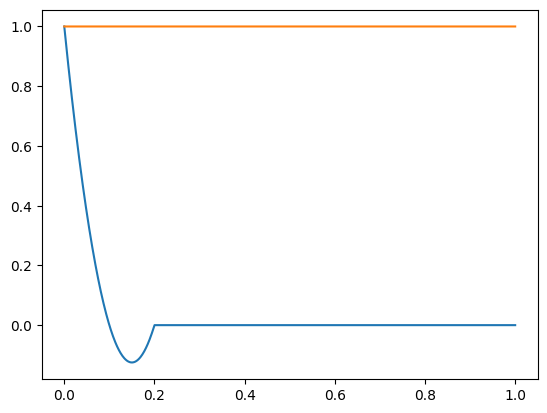

In [8]:
# model = nodal_values[0]*phi_0+nodal_values[1]*phi_1+nodal_values[2]*phi_2+nodal_values[2]*phi_3+nodal_values[3]*phi_4+nodal_values[4]*phi_5+nodal_values[4]*phi_6+ nodal_values[5]*phi_7+nodal_values[6]*phi_8+nodal_values[6]*phi_9+nodal_values[7]*phi_10+nodal_values[8]*phi_11+nodal_values[8]*phi_12+nodal_values[9]*phi_13+nodal_values[10]*phi_14
# plt.plot(x,phi_0)
# plt.plot(x,phi_1)
# plt.plot(x,phi_2)
# plt.plot(x,phi_3)
# plt.plot(x,phi_4)
# plt.plot(x,phi_5)
# plt.plot(x,phi_6)
# plt.plot(x,phi_7)
# plt.plot(x,phi_8)
# plt.plot(x,phi_9)
# plt.plot(x,phi_10)
# plt.plot(x,phi_11)
# plt.plot(x,phi_12)
# plt.plot(x,phi_13)
plt.plot(x,phi[0,0])
plt.plot(x,model)